# TT-29 — TF-IDF: tự động chuyển ticket về đúng bộ phận

**Bài toán.** Trung tâm CSKH nhận 2.000 ticket/ngày, ~18% bị chuyển sai bộ phận ít nhất 1 lần. Cần mô hình phân loại
**chạy trên CPU, < 5 ms / ticket, train lại trong vài giây, giải thích được**, kèm cơ chế: độ tin cậy thấp thì để người
quyết định. Luyện trên **20 Newsgroups** (18.846 bài, 20 nhóm), cấu trúc giống kho ticket: văn bản tự do + nhóm đích.

**Câu hỏi chính:** (1) rò rỉ qua headers / footers / quotes làm accuracy ảo bao nhiêu? (2) Sau khi bỏ rò rỉ, TF-IDF đạt
bao nhiêu, và đổi lấy tốc độ / khả năng giải thích thế nào?

Notebook gọi các hàm trong `src/`. Chạy toàn bộ mất ~15 phút trên CPU (riêng LSA 1.000 chiều ~7 phút).

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

import preprocess as P
import train as T

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
R = T.REPORTS_DIR

## 1. ⭐ Rò rỉ qua headers / footers / quotes

**Logic code (`run_leakage`):** cùng một pipeline `TfidfVectorizer(ngram (1,2), min_df=3, max_df=0.8, sublinear_tf,
max_features=50.000) + LinearSVC(C=1)`, fit trên train, đo trên test. Chỉ khác phần văn bản được giữ lại:

```python
fetch_20newsgroups(subset, remove=())                                 # giu nguyen
fetch_20newsgroups(subset, remove=("headers",))                       # bo From, Subject, Organization, Lines...
fetch_20newsgroups(subset, remove=("headers", "footers"))             # + bo chu ky sau dong "--"
fetch_20newsgroups(subset, remove=("headers", "footers", "quotes"))   # + bo dong trich "> ..." / "X writes:"
# + bien the them: bo ca 3 nhung GIU dong Subject (ticket that luon co tieu de)
```

[leak] Giu nguyen (khong bo gi): acc test 0.8534


[leak] Bo headers: acc test 0.8178


[leak] Bo headers + footers: acc test 0.7981


[leak] Bo headers + footers + quotes: acc test 0.6818


[leak] Bo ca 3 nhung GIU Subject: acc test 0.8083


,bien_the,accuracy_test,macro_f1_test,so_tu_TB,van_ban_rong_train
0,Giu nguyen (khong bo gi),0.8534,0.8472,287.4701,0
1,Bo headers,0.8178,0.8104,265.7229,18
2,Bo headers + footers,0.7981,0.7901,247.2206,18
3,Bo headers + footers + quotes,0.6818,0.6694,185.8274,300
4,Bo ca 3 nhung GIU Subject,0.8083,0.8009,190.8539,0


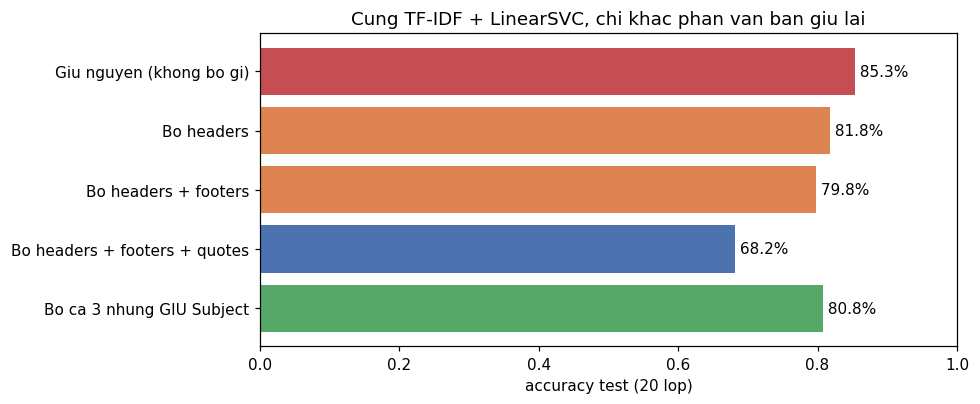

Top 10 tu cua LinearSVC khi GIU NGUYEN van ban:


,top 10 tu
alt.atheism,"atheism, atheists, islamic, keith, rushdie, edu keith, atheist, wingate, mathew, religion"
comp.graphics,"graphics, 3d, image, images, pov, animation, polygon, tiff, 3do, format"
comp.os.ms-windows.misc,"windows, for windows, cica, win3, win, file, files, winqvt, microsoft, program manager"
comp.sys.ibm.pc.hardware,"gateway, pc, bios, ide, 486, bus, vlb, motherboard, controller, monitor"
comp.sys.mac.hardware,"mac, apple, powerbook, quadra, duo, centris, lc, iisi, macs, lciii"
comp.windows.x,"motif, widget, window, x11r5, server, xterm, xlib, x11, sun, r5"
misc.forsale,"sale, for sale, forsale, shipping, wanted, offer, sell, subject wanted, if interested, asking"
rec.autos,"car, cars, toyota, ford, auto, dealer, the car, warning please, engine, re warning"
rec.motorcycles,"dod, bike, bikes, motorcycle, riding, ride, bmw, motorcycles, kawasaki, ama"
rec.sport.baseball,"baseball, phillies, stadium, cubs, runs, sox, pitching, tigers, ball, braves"


In [2]:
leak, leak_top = T.run_leakage()
display(leak)
display(Image(R / "leakage_comparison.png"))
print("Top 10 tu cua LinearSVC khi GIU NGUYEN van ban:")
display(leak_top.apply(lambda r: ", ".join(r.astype(str)), axis=1).to_frame("top 10 tu"))

**Đọc kết quả:**

| Biến thể | Accuracy test | Mất so với bản gốc |
|---|---:|---:|
| Giữ nguyên | **85,3%** | — |
| Bỏ headers | 81,8% | −3,6 điểm |
| Bỏ headers + footers | 79,8% | −5,5 |
| **Bỏ cả 3** | **68,2%** | **−17,2** |
| Bỏ cả 3 nhưng giữ Subject | 80,8% | −4,5 |

* **Rò rỉ là thật: 17 điểm accuracy là ảo.** Nhưng nó *không* đến từ dòng `Newsgroups: comp.graphics` như đề mô tả:
  dòng đó chỉ có ở **45 / 11.314** bài. Rò rỉ đến từ **người viết**. Top từ của bản gốc là tên người và máy chủ:
  `keith`, `mathew` (atheism), `clh`, `athos`, `rutgers edu` (địa chỉ người kiểm duyệt nhóm soc.religion.christian),
  `serdar`, `argic` (một bot spam ở nhóm mideast), `kaldis`, `cramer`, `teel` (politics.misc). Model học "ai viết" chứ
  không học "viết về gì".
* **Quotes đóng góp nhiều nhất (−11,6 điểm):** đoạn trích bài trước cùng chủ đề gần như cho không đáp án.
* **Subject là thông tin hợp lệ:** giữ riêng tiêu đề lấy lại 12,6 điểm (68,2% → 80,8%). Với ticket thật, tiêu đề do
  khách gõ nên **được phép dùng**. Còn tên khách, chữ ký nhân viên, trích dẫn email trước, mã hàng đợi (tương đương
  headers) thì phải bỏ.
* Từ đây trở đi: **chỉ dùng bản bỏ cả 3** (đúng yêu cầu của đề, để so với mức tham chiếu 69–73%) và **ẩn danh** email /
  URL / số điện thoại còn sót trong thân bài.

## 2. EDA

**Logic code (`preprocess.load` → `run_eda`):** bỏ cả 3 phần, ẩn danh (`an_danh`: email → `EMAIL`, URL → `URL`,
số điện thoại dạng Mỹ → `PHONE`). Tách 20% train làm val (stratify). Đếm từ bằng `CountVectorizer(stop_words="english")`.

[load] train 9,051 | val 2,263 | test 7,532 | train day du 11,314


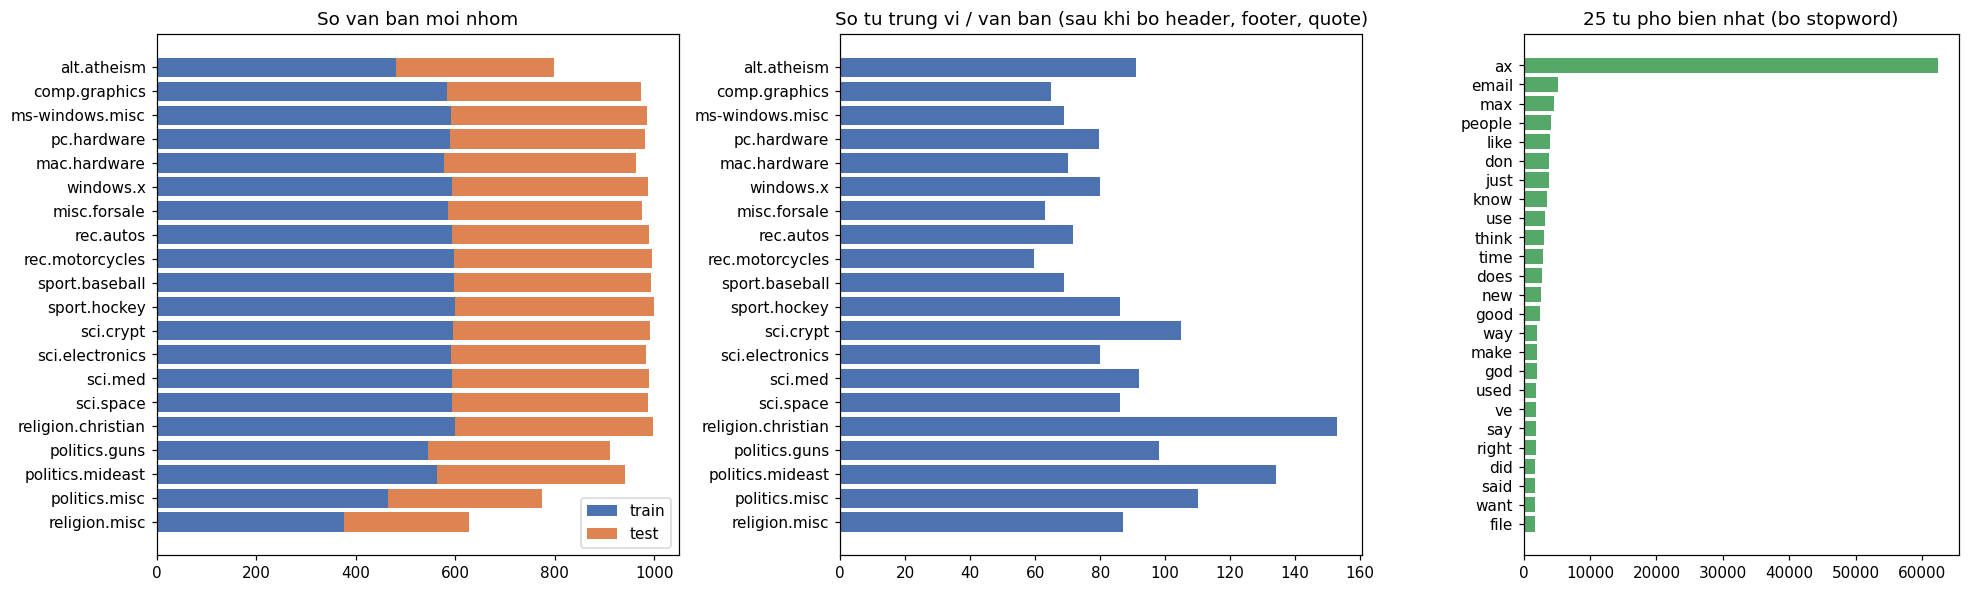

,train,test,so_tu_TB,so_tu_trung_vi,so_van_ban_rong
nhom,,,,,
alt.atheism,480,319,196.9337,91.0000,20
comp.graphics,584,389,197.3597,65.0000,18
comp.os.ms-windows.misc,591,394,134.8447,69.0000,38
comp.sys.ibm.pc.hardware,590,392,125.6548,79.5000,18
comp.sys.mac.hardware,578,385,111.5846,70.0000,34
comp.windows.x,593,395,220.0182,80.0000,6
misc.forsale,585,390,107.8974,63.0000,16
rec.autos,594,396,113.2374,71.5000,53
rec.motorcycles,598,398,100.1657,59.5000,27


In [3]:
d = T.load()
eda = T.run_eda(d)
display(Image(R / "eda.png"))
display(pd.read_csv(R / "eda_theo_lop.csv", index_col=0))

**Đọc kết quả:**

* **Gần cân bằng:** 377–600 bài train / nhóm. Ít nhất là talk.religion.misc (377) và talk.politics.misc (465).
  Dummy classifier chỉ được 5,3%.
* **Độ dài lệch mạnh:** trung vị 59–153 từ / bài nhưng TB 100–354, vì có bài rất dài. talk.politics.mideast và
  soc.religion.christian dài nhất.
* **300 bài train (2,7%) rỗng hoàn toàn** sau khi bỏ header / footer / quote: đó là bài chỉ có trích dẫn, hoặc chỉ có
  chữ ký. Test có 215 bài rỗng. Mô hình **không thể** phân loại đúng những bài này (bước 11).
* **Từ phổ biến nhất là `ax` (62.387 lần)** nhưng chỉ đến từ **20 bài** ở comp.os.ms-windows.misc: một file nhị phân mã
  hoá uuencode bị chia 14 phần (`MAX>'AX>'AX>...`). Đây là rác. `sublinear_tf` (1 + log TF) giúp nó không áp đảo.
  Tiếp theo là `EMAIL` (5.162, chính là địa chỉ email đã ẩn danh), rồi các từ chung chung như people, like, know.

## 3. Baseline: Dummy + Naive Bayes

Cùng TF-IDF mặc định của đề. `MultinomialNB` là bản kinh điển. `ComplementNB` là biến thể dành riêng cho văn bản (ước
lượng từ các lớp *còn lại*, ổn định hơn khi số tài liệu mỗi lớp lệch nhau).

In [4]:
base = T.run_baselines(d)
base

,mo_hinh,acc_val,acc_test,macro_f1_test,thoi_gian_fit_s
0,Dummy (doan lop dong nhat),0.0530,0.0530,0.0050,12.9031
1,"MultinomialNB (alpha=0,01)",0.7221,0.6589,0.6428,12.7106
2,"ComplementNB (alpha=0,3)",0.7534,0.7055,0.6855,13.3893


**Đọc kết quả:** Dummy **5,3%** (≈ 1/20). MultinomialNB **65,9%**, ComplementNB **70,6%** test. Chỉ với Naive Bayes đã
nằm trong mức tham chiếu 69–73% của đề.

## 4–5. TF-IDF + LinearSVC: khảo sát tham số vectorizer

**Logic code (`run_sweep`):** lưới `ngram_range` (1,1) / (1,2) × `min_df` 1 / 3 / 5 × `sublinear_tf` True / False
(**không** giới hạn `max_features`, để thấy số đặc trưng thật), `max_df=0.8`, `LinearSVC(C=1)`. Fit trên train 80%, đo
trên val. Sau đó thử `max_features` 20k / 50k / không giới hạn trên cấu hình tốt nhất.

,ngram_range,min_df,sublinear_tf,so_dac_trung,acc_val,macro_f1_val,thoi_gian_fit_s,max_features
0,"(1, 1)",1,True,87126,0.7676,0.7602,5.2288,NaN
1,"(1, 1)",1,False,87126,0.7649,0.7591,5.1942,NaN
2,"(1, 1)",3,True,22773,0.7534,0.7468,4.4917,NaN
3,"(1, 1)",3,False,22773,0.7486,0.7417,4.5387,NaN
4,"(1, 1)",5,True,15275,0.7446,0.7378,4.8794,NaN
5,"(1, 1)",5,False,15275,0.7375,0.7306,4.4807,NaN
6,"(1, 2)",1,True,785901,0.7631,0.7523,24.9161,NaN
7,"(1, 2)",1,False,785901,0.7654,0.7555,24.7848,NaN
8,"(1, 2)",3,True,97834,0.7508,0.7423,12.0208,NaN
9,"(1, 2)",3,False,97834,0.7455,0.7393,11.6796,NaN


Chon: {'ngram_range': (1, 1), 'min_df': 1, 'sublinear_tf': True, 'max_features': None}


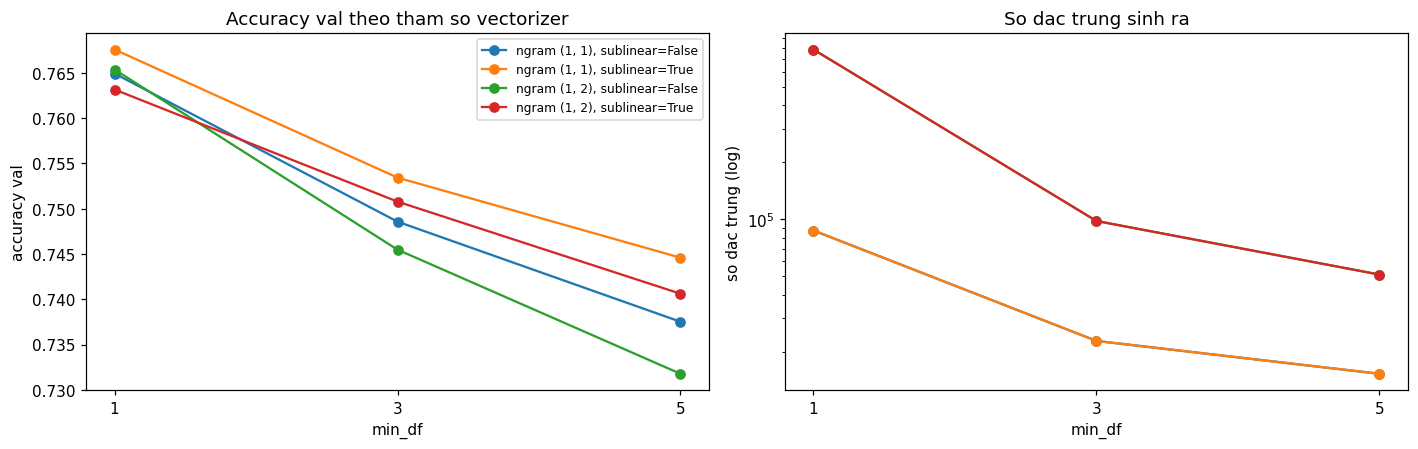

In [5]:
sweep, best = T.run_sweep(d)
display(sweep)
print("Chon:", best)
display(Image(R / "khao_sat_vectorizer.png"))

**Đọc kết quả:**

| | min_df = 1 | min_df = 3 | min_df = 5 |
|---|---:|---:|---:|
| Số đặc trưng, unigram | 87.126 | 22.773 | 15.275 |
| Số đặc trưng, uni + bigram | 785.901 | 97.834 | 51.015 |
| Accuracy val tốt nhất | **0,768** (unigram, sublinear) | 0,753 | 0,745 |

* **`min_df=1` tốt nhất**, ngược với cảnh báo của đề ("giữ cả lỗi chính tả → overfit"). LinearSVC có regularization
  nên chịu được 87k chiều. Nhưng chênh chỉ **1,4 điểm** so với `min_df=3`, trong khi số đặc trưng gấp **3,8 lần**.
  Nếu bộ nhớ quan trọng, `min_df=3` là lựa chọn hợp lý.
* **Bigram không giúp** (0,763 so với 0,768) mà tăng số đặc trưng 9 lần ở `min_df=1` và gần 5 lần thời gian fit.
  Với chủ đề tin tức, từ đơn đã đủ phân biệt.
* **`sublinear_tf=True` tốt hơn ở 5/6 cấu hình** (+0,3 đến +0,9 điểm): giảm ảnh hưởng của từ lặp nhiều lần (như `ax`).
* `max_features`: 20k → 50k → không giới hạn cho 0,749 → 0,764 → 0,768. **Chọn: unigram, min_df=1, sublinear, không giới
  hạn** (98.117 đặc trưng khi fit trên toàn bộ train).

## 6. So sánh 3 bộ phân loại trên cùng TF-IDF

**Logic code (`run_classifiers`):** mỗi bộ chọn 1 siêu tham số trên val (ComplementNB `alpha`, LogisticRegression `C`,
LinearSVC `C`), rồi fit lại trên **toàn bộ train** và đo trên test.

In [6]:
clf, m = T.run_classifiers(d, best)
clf

[clf] ComplementNB (0.3): val 0.7883 test 0.7179 (3.9s)


[clf] LogisticRegression (3): val 0.7503 test 0.6912 (60.3s)


[clf] LinearSVC (1.0): val 0.7676 test 0.6973 (6.0s)


,mo_hinh,tham_so_chon,acc_val_theo_tham_so,acc_val,acc_test,macro_f1_test,thoi_gian_fit_s
0,ComplementNB,0.3000,"{""0.1"": 0.7844, ""0.3"": 0.7883, ""1.0"": 0.7733}",0.7883,0.7179,0.6979,3.8889
1,LogisticRegression,3.0000,"{""3"": 0.7503, ""10"": 0.7468, ""30"": 0.7503}",0.7503,0.6912,0.6783,60.2937
2,LinearSVC,1.0000,"{""0.1"": 0.7521, ""0.3"": 0.7654, ""1.0"": 0.7676}",0.7676,0.6973,0.6854,6.0192


**Đọc kết quả:**

| | Tham số chọn | Accuracy val | **Accuracy test** | Macro-F1 test | Thời gian fit |
|---|---|---:|---:|---:|---:|
| **ComplementNB** | alpha 0,3 | **0,788** | **0,718** | 0,698 | **3,7 s** |
| LogisticRegression | C 3 | 0,750 | 0,691 | 0,678 | 62 s |
| LinearSVC | C 1 | 0,768 | 0,697 | 0,685 | 7 s |

**ComplementNB thắng** cả val lẫn test (+2 điểm), nhanh nhất, ngược với nhận định "LinearSVC thường thắng" của đề.
Một lý do hợp lý: sau khi bỏ header / footer / quote, nhiều bài rất ngắn (32% bài test có ≤ 50 từ), và Naive Bayes
thường làm tốt với văn bản ngắn. Val cao hơn test ~7 điểm ở mọi mô hình, vì val lấy ngẫu nhiên **cùng thời kỳ** với train, còn test là các
bài đăng **sau** (sklearn chia sẵn theo thời gian). Đây là lệch phân phối theo thời gian, giống hệt ticket thật.

## 9b. Chọn bản triển khai: cần XÁC SUẤT và < 5 ms / ticket

Hai ràng buộc cứng của bài toán: (1) có xác suất để áp ngưỡng tin cậy; (2) dự đoán 1 ticket < 5 ms. So 5 cách lấy xác
suất (`run_deploy_options`). Đo độ trễ = trung vị của 300 lần gọi `predict_proba([1 ticket])` (gồm cả TF-IDF).

```python
CalibratedClassifierCV(LinearSVC(C=1), cv=3)                  # 3 mo hinh, du doan = trung binh 3
CalibratedClassifierCV(LinearSVC(C=1), cv=3, ensemble=False)  # 1 mo hinh tren toan bo train + bo hieu chinh
                                                              # hoc tu du doan cross-val -> nhanh gap ~3 lan
```
Trong các cách đạt < 5 ms, chọn cách có accuracy val cao nhất.

In [7]:
deploy, final = T.run_deploy_options(d, best, m["C"], m["alpha"])
deploy

[deploy] ComplementNB, xac suat goc: acc test 0.7179 | 12.3 ms | tu dong 3.0%


[deploy] ComplementNB + Calibrated (cv=3): acc test 0.7187 | 41.6 ms | tu dong 52.1%


[deploy] ComplementNB + Calibrated (cv=3, ensemble=False): acc test 0.7172 | 14.0 ms | tu dong 57.5%


[deploy] LinearSVC + Calibrated (cv=3): acc test 0.7002 | 6.7 ms | tu dong 53.3%


[deploy] LinearSVC + Calibrated (cv=3, ensemble=False): acc test 0.6982 | 3.2 ms | tu dong 60.6%


[deploy] chon: LinearSVC + Calibrated (cv=3, ensemble=False)


,cach,acc_val,acc_test,tin_cay_TB,ti_le_tu_dong_0.6,acc_phan_tu_dong_0.6,du_doan_1_ticket_ms,dat_duoi_5ms,thoi_gian_fit_s
0,"ComplementNB, xac suat goc",0.7883,0.7179,0.1656,0.0300,0.9867,12.2679,False,3.3015
1,ComplementNB + Calibrated (cv=3),0.7914,0.7187,0.5723,0.5208,0.9330,41.6458,False,4.4092
2,"ComplementNB + Calibrated (cv=3, ensemble=False)",0.7936,0.7172,0.6056,0.5753,0.9137,14.0298,False,4.3206
3,LinearSVC + Calibrated (cv=3),0.7645,0.7002,0.5843,0.5327,0.9105,6.7174,False,8.8710
4,"LinearSVC + Calibrated (cv=3, ensemble=False)",0.7636,0.6982,0.6350,0.6062,0.8857,3.1773,True,11.5068


**Đọc kết quả:**

| Cách lấy xác suất | Accuracy test | Tự động ở ngưỡng 0,6 (accuracy) | 1 ticket |
|---|---:|---:|---:|
| ComplementNB, xác suất gốc | 71,8% | **3,0%** (98,7%) | 12 ms |
| ComplementNB + Calibrated cv=3 | **71,9%** | 52,1% (**93,3%**) | 41 ms ❌ |
| ComplementNB + Calibrated ensemble=False | 71,7% | 57,5% (91,4%) | 14 ms ❌ |
| LinearSVC + Calibrated cv=3 (code mẫu của đề) | 70,0% | 53,3% (91,1%) | 6,7–7,3 ms ❌ |
| **LinearSVC + Calibrated ensemble=False** ← chọn | 69,8% | **60,6%** (88,6%) | **2,8–3,2 ms ✅** |

* **Xác suất gốc của Naive Bayes vô dụng cho cơ chế ngưỡng:** độ tin cậy TB chỉ 0,17, chỉ 3% ticket vượt 0,6. Phải
  hiệu chỉnh (calibrate).
* **Code mẫu của đề (`cv=3`) không đạt 5 ms** (~7 ms), vì mỗi dự đoán chạy 3 mô hình. `ensemble=False` chạy 1 mô hình
  nên chỉ còn ~3 ms.
* **Đánh đổi:** NB đã hiệu chỉnh chính xác hơn ~2 điểm nhưng chậm 5–15 lần, không đạt yêu cầu tốc độ. Bản triển khai là
  **LinearSVC + CalibratedClassifierCV(ensemble=False)**, lưu ở `models/tfidf_pipeline.joblib`.

## 7. ⭐ Top 15 từ đặc trưng mỗi lớp

**Logic code (`run_top_words`):** LinearSVC có 1 vector trọng số cho mỗi lớp (one-vs-rest). 15 từ có trọng số **dương
lớn nhất** là những từ đẩy văn bản về lớp đó mạnh nhất. Đây cũng là cách **giải thích** cho nhân viên vì sao ticket bị
chuyển vào bộ phận này.

,top 15 tu
alt.atheism,"atheism, motto, bobby, religion, atheists, islam, islamic, nanci, deletion, cruel, punishment, atheist, species, loa..."
comp.graphics,"graphics, 3d, image, images, 68070, pov, animation, tiff, cview, 3do, polygons, viewer, sphere, polygon, phigs"
comp.os.ms-windows.misc,"windows, cica, win3, risc, mfc, ini, file, microsoft, w4wg, nt, smartdrv, win, winqvt, os2, characters"
comp.sys.ibm.pc.hardware,"vlb, 486, ide, fastmicro, bios, cmos, gateway, f550iw, pc, t560i, os, controller, gw2000, irq, adaptec"
comp.sys.mac.hardware,"mac, apple, powerbook, quadra, centris, se, duo, adb, lc, nubus, c650, iisi, lciii, simms, 040"
comp.windows.x,"motif, server, widget, xterm, x11r5, window, mit, widgets, xlib, x11, clients, openwindows, terminals, sun, binaries"
misc.forsale,"sale, shipping, offer, sell, interested, condition, inguiry, asking, 2190, buyer, forsale, includes, summer, new, pay"
rec.autos,"car, cars, dealer, ford, oil, vw, toyota, gt, autos, sho, ites, engine, opel, saturn, beamers"
rec.motorcycles,"bike, dod, bikes, ride, motorcycle, helmet, riding, motorcycles, harley, bmw, dog, zx, kawasaki, biker, moto"
rec.sport.baseball,"baseball, stadium, phillies, cubs, braves, alomar, ball, mets, runs, royals, sox, yankees, pitching, uniforms, nl"


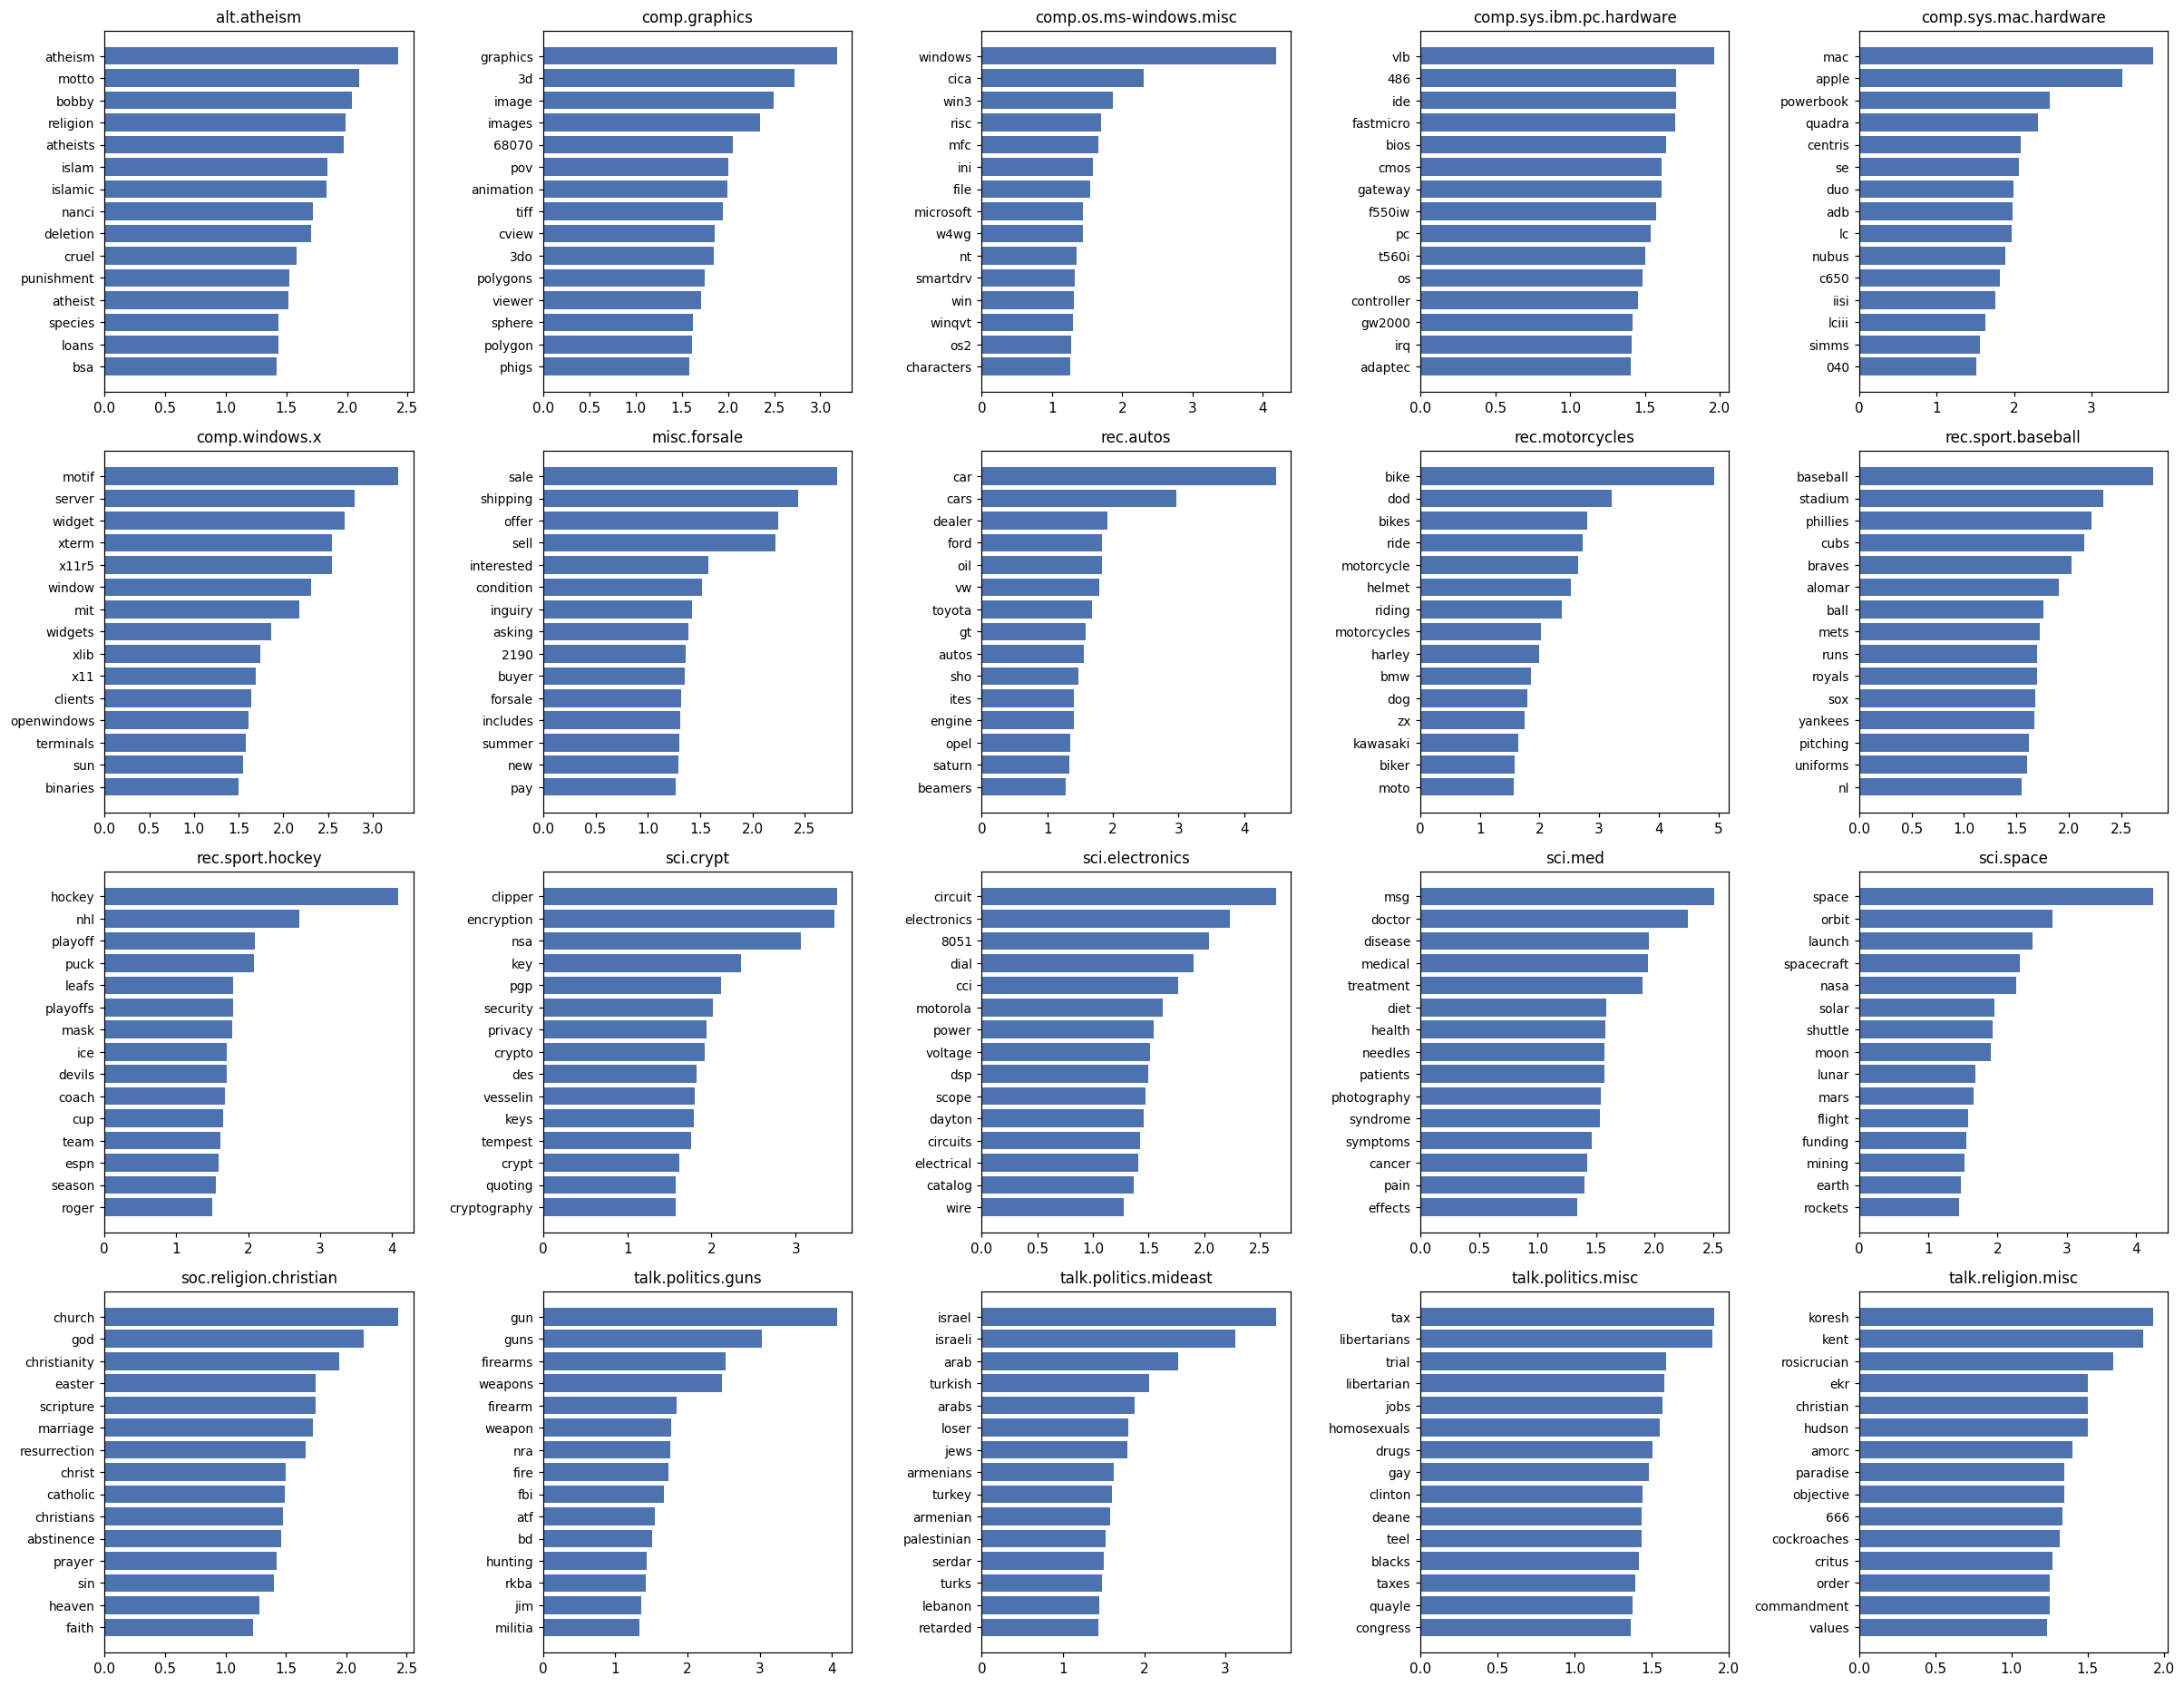

In [8]:
top = T.run_top_words(d, m["svc"])
display(top.apply(lambda r: ", ".join(r.astype(str)), axis=1).to_frame("top 15 tu"))
display(Image(R / "top_tu_moi_lop.png"))

**Đọc kết quả:**

* **Phần lớn hợp lý:** comp.graphics → graphics, 3d, image, pov, tiff, polygon. sci.space → space, orbit, launch, nasa,
  shuttle, moon. rec.sport.hockey → hockey, nhl, playoff, puck, leafs. talk.politics.guns → gun, firearms, nra, atf.
  misc.forsale → sale, shipping, offer, condition, asking.
* **Rò rỉ còn sót, do tên người trong thân bài:** `bobby`, `nanci` (alt.atheism), `vesselin` (sci.crypt), `serdar`
  (mideast), `kent`, `ekr`, `critus` (talk.religion.misc), `deane`, `teel` (politics.misc), `roger` (hockey). Bỏ header
  không xoá được tên khi người viết tự ký hoặc được gọi tên trong bài. Với ticket thật: **phải ẩn danh cả tên khách và
  tên nhân viên trong thân ticket**, không chỉ email / số điện thoại.
* **Từ vựng tranh cãi:** `loser`, `retarded` (mideast), `homosexuals`, `blacks` (politics.misc): model học cả giọng
  điệu tranh cãi của nhóm.
* **Mã sản phẩm:** `f550iw`, `t560i`, `gw2000` (pc.hardware), `c650` (mac): rất đặc hiệu nhưng sẽ lỗi thời khi có sản
  phẩm mới, nên cần **train lại định kỳ** (rất rẻ: vài giây).

## 8. Ma trận nhầm lẫn

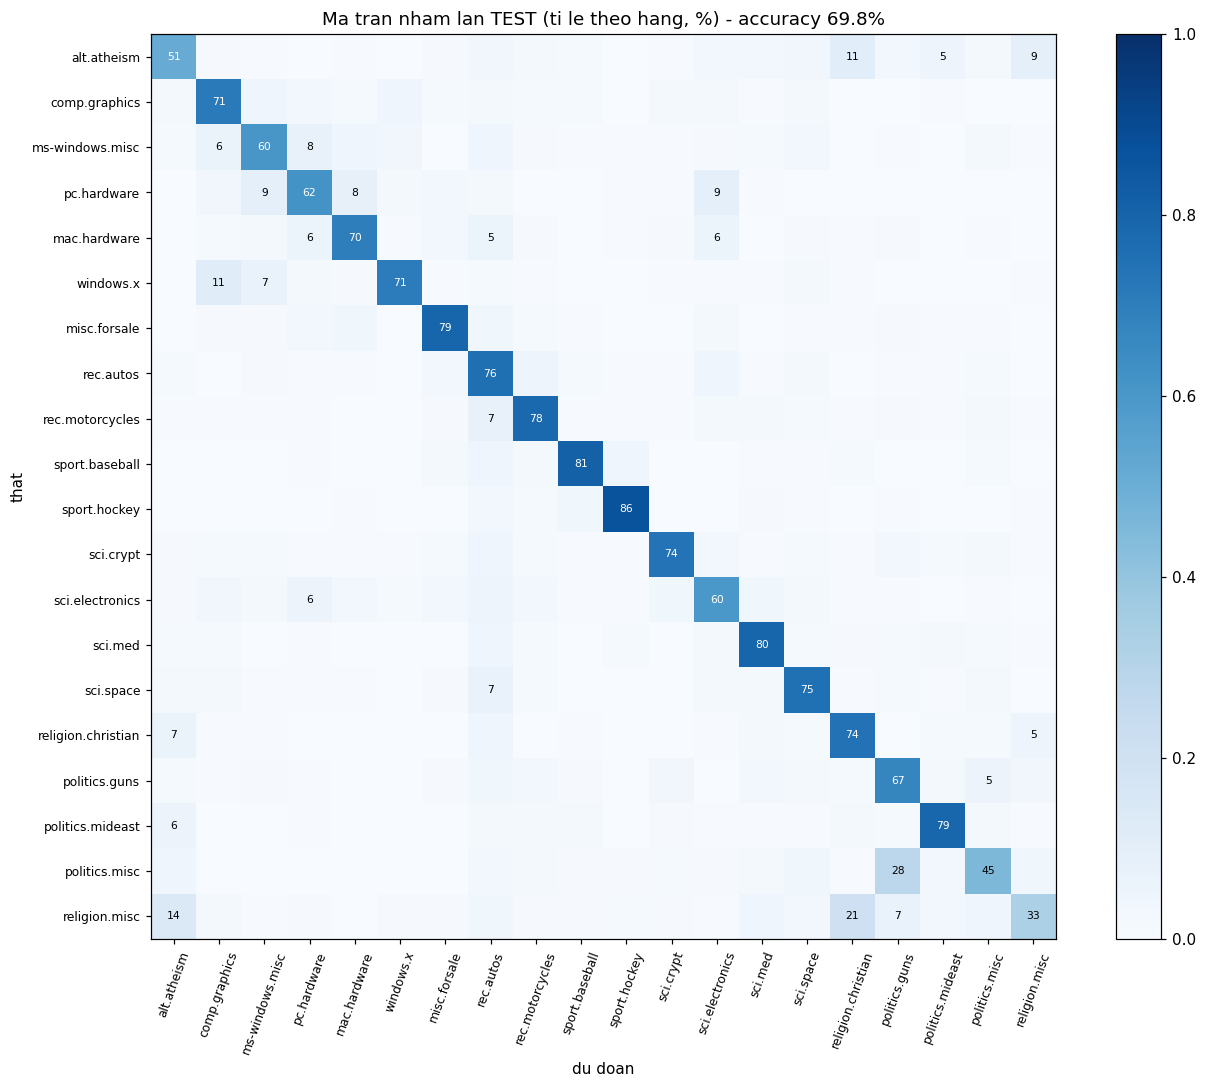

,that,du_doan,so_van_ban,ti_le_cua_lop_that
358,talk.politics.misc,talk.politics.guns,87,0.2806
376,talk.religion.misc,soc.religion.christian,52,0.2072
96,comp.windows.x,comp.graphics,45,0.1139
361,talk.religion.misc,alt.atheism,35,0.1394
68,comp.sys.ibm.pc.hardware,sci.electronics,34,0.0867
14,alt.atheism,soc.religion.christian,34,0.1066
59,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,34,0.0867
60,comp.sys.ibm.pc.hardware,comp.sys.mac.hardware,32,0.0816
40,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,30,0.0761
18,alt.atheism,talk.religion.misc,28,0.0878


,nhom,recall,so_van_ban_test
0,alt.atheism,0.5110,319
1,comp.graphics,0.7147,389
2,comp.os.ms-windows.misc,0.6041,394
3,comp.sys.ibm.pc.hardware,0.6199,392
4,comp.sys.mac.hardware,0.6987,385
5,comp.windows.x,0.7063,395


In [9]:
pairs, per = T.run_confusion(d, final)
display(Image(R / "confusion_matrix.png"))
display(pairs.head(10))
display(per.head(6))

**Đọc kết quả (bản triển khai, test 69,8%):**

| Cặp hay nhầm (thật → dự đoán) | Số bài | % của lớp thật |
|---|---:|---:|
| talk.politics.misc → talk.politics.guns | 87 | **28%** |
| talk.religion.misc → soc.religion.christian | 52 | 21% |
| comp.windows.x → comp.graphics | 45 | 11% |
| talk.religion.misc → alt.atheism | 35 | 14% |
| comp.sys.ibm.pc.hardware → sci.electronics / ms-windows / mac.hardware | 34 / 34 / 32 | 8–9% mỗi cặp |

* Nhầm theo **cụm chủ đề**: 3 nhóm tôn giáo (atheism / christian / religion.misc), 2 nhóm chính trị (misc / guns), cụm
  máy tính (pc / mac / ms-windows / windows.x / graphics / electronics).
* Recall thấp nhất: **talk.religion.misc 33%**, talk.politics.misc 45%, alt.atheism 51%. Đây là các nhóm "misc" / thảo
  luận chung, vốn chồng lấn nội dung với nhóm chuyên biệt hơn. Cao nhất: rec.sport.hockey 86%.
* Với ticket: đây là dấu hiệu nên **gộp hoặc định nghĩa lại bộ phận** có nội dung chồng lấn, thay vì cố tăng accuracy.

## 9. ⭐ Cơ chế tin cậy: max(proba) < 0,6 → chuyển người

,nguong,ti_le_tu_dong,acc_phan_tu_dong,ti_le_can_nguoi,acc_phan_can_nguoi_neu_de_model
6,0.4000,0.8201,0.8002,0.1799,0.2332
8,0.5000,0.7225,0.8434,0.2775,0.3201
10,0.6000,0.6062,0.8857,0.3938,0.4096
12,0.7000,0.4855,0.9185,0.5145,0.4903
14,0.8000,0.3128,0.9448,0.6872,0.5860
16,0.9000,0.0765,0.9722,0.9235,0.6755


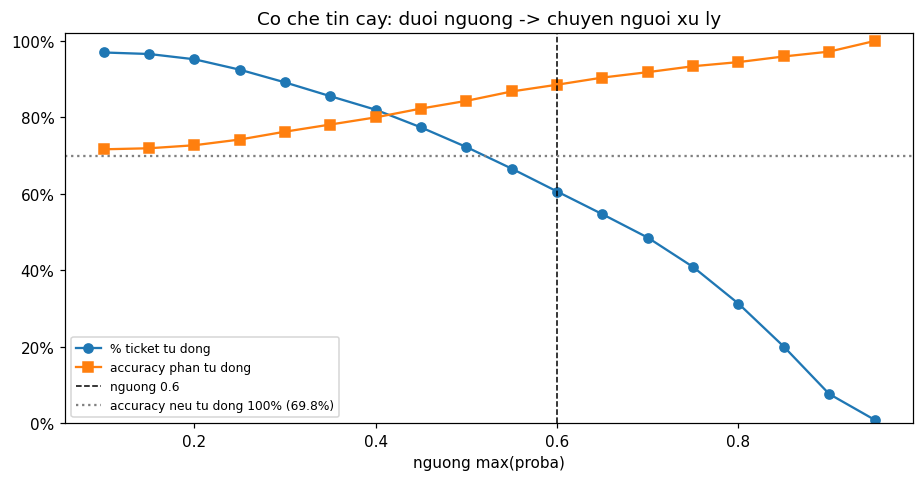

In [10]:
thr = T.run_threshold(d, final)
display(thr[thr["nguong"].isin([0.4, 0.5, 0.6, 0.7, 0.8, 0.9])])
display(Image(R / "nguong_tin_cay.png"))

**Đọc kết quả:**

| Ngưỡng | % tự động | Accuracy phần tự động | % cần người | Accuracy model trên phần chuyển người |
|---:|---:|---:|---:|---:|
| 0,5 | 72,3% | 84,3% | 27,7% | 32,0% |
| **0,6** | **60,6%** | **88,6%** | **39,4%** | 41,0% |
| 0,7 | 48,6% | 91,9% | 51,4% | 49,0% |
| 0,8 | 31,3% | 94,5% | 68,7% | 58,6% |

* **Ở ngưỡng 0,6:** 60,6% ticket chuyển tự động với độ chính xác **88,6%** (so với 69,8% nếu tự động 100%). 39,4% còn
  lại chuyển người, và trên phần này model chỉ đúng 41%: đúng là những ca khó.
* Với 2.000 ticket/ngày: ~1.210 tự động (~138 sai, tức 11,4%, thấp hơn mức 18% bị chuyển sai hiện nay), ~790 do người
  đọc.
* Muốn tự động hoá cao hơn mà vẫn chính xác thì cần thêm thông tin: **tiêu đề ticket** (bước 1 cho thấy Subject +12,6
  điểm), danh mục khách tự chọn, sản phẩm liên quan.

## 10. Thời gian

In [11]:
timing = T.run_timing(d, final)
pd.Series(timing).to_frame("gia_tri")

,gia_tri
du_doan_1_van_ban_ms_trung_vi,2.9293
du_doan_1_van_ban_ms_p95,5.6432
du_doan_1_van_ban_ms_max,38.6730
du_doan_ca_test_s,1.5937
van_ban_moi_giay_batch,"4,726.1170"
nap_model_s,0.3107
kich_thuoc_model_MB,17.7858


**Đọc kết quả:** dự đoán 1 ticket (TF-IDF + LinearSVC + hiệu chỉnh) **trung vị ~3 ms** (2,9–3,3 ms qua 2 lần đo), p95 5,1–5,6 ms ✅
(yêu cầu < 5 ms tính theo trung vị; p95 nhích quá ngưỡng một chút, đỉnh khi máy bận). Theo lô: **~4.000–4.700 ticket/giây**. Train lại toàn bộ 11.314 văn bản: ~12 s.
Model 17,8 MB, nạp trong 0,3 s.

## 11. Phân tích 10 ca sai

In [12]:
errs, by_len = T.run_errors(d, final)
display(errs)
display(by_len)

,loai,that,du_doan,tin_cay,so_tu,text_200_ky_tu
0,sai tu tin,alt.atheism,sci.crypt,0.9432,194,"The CLIPPER initiative is an announcement by Clinton that all the ""secure"" voice phones will use the same crypto chi..."
1,sai tu tin,comp.graphics,comp.os.ms-windows.misc,0.9375,142,"There are some tricks to installing ATM to windows... install them first to dos, then run the ATM control panel to g..."
2,sai tu tin,talk.religion.misc,sci.space,0.9323,3515,The following partial summary of a Theory of the Universe includes a little-known description of the CREATION of our...
3,sai tu tin,comp.windows.x,comp.os.ms-windows.misc,0.9258,261,"I use it all day every day (maintaining our ftp site and answering mail via EMAIL ), and I can honestly say that in ..."
4,sai tu tin,alt.atheism,soc.religion.christian,0.9221,193,"I found this little gem, I don't know if anyone has any interest/comments... ---------------------------------------..."
5,sai ngau nhien,misc.forsale,comp.sys.mac.hardware,0.5927,28,"For Sale I have 4 (Four) 1 Meg SIMMS (100ns) for the Macintosh. If you want to upgrade that Mac IIsi, IIci, or whate..."
6,sai ngau nhien,talk.religion.misc,soc.religion.christian,0.5943,483,-*---- No. It follows from the fact that most Christians' choice of interpretation stems from a mix of beliefs that ...
7,sai ngau nhien,sci.med,talk.politics.mideast,0.3099,56,"When I was a school boy, my biology teacher told us of an incident in which a couple were very passionate without ac..."
8,sai ngau nhien,talk.politics.guns,sci.med,0.2232,68,A great deal of documentation exists on exactly that phenomenon. Especially regarding Vietnam and the Mai Lai (sp?) ...
9,sai ngau nhien,comp.windows.x,sci.space,0.6869,64,I need some help in tracking down a dvi viewer for X. I have xdvi but we have not got the X libraries and includes i...


,so_van_ban,accuracy
nhom_do_dai,,
rong,215,0.0977
1-10,263,0.3536
11-50,1946,0.6007
51-200,3623,0.7601
>200,1485,0.8229


**Đọc kết quả:**

| # | Thật → dự đoán | Tin cậy | Nguyên nhân |
|---|---|---:|---|
| 1 | atheism → **sci.crypt** | 0,94 | Bài nói về **Clipper chip** đăng nhầm nhóm / cross-post. Nội dung đúng là crypto: **nhãn sai, model đúng** |
| 2 | graphics → ms-windows | 0,94 | Cài font ATM **trong Windows**: chủ đề chồng lấn thật |
| 3 | religion.misc → sci.space | 0,93 | Bài 3.515 từ về "thuyết vũ trụ Larsonian": nội dung là thiên văn |
| 4 | windows.x → ms-windows | 0,93 | Nói về mạng TCP/IP và độ ổn định máy, không có từ đặc trưng của X Window |
| 5 | atheism → christian | 0,92 | Chuyển tiếp thư của một người Kitô giáo: từ vựng hoàn toàn Kitô giáo |
| 6 | forsale → mac.hardware | 0,59 | "Bán 4 SIMM cho Mac": **thuộc cả 2 nhóm**, bài toán thật là đa nhãn |
| 7 | religion.misc → christian | 0,59 | Tranh luận thần học: 2 nhóm chồng lấn |
| 8 | sci.med → mideast | 0,31 | Chuyện kể lạc đề, tin cậy thấp → **đã được chuyển người** ở ngưỡng 0,6 |
| 9 | guns → sci.med | 0,22 | Bàn về thảm sát Mỹ Lai, lạc đề → **đã chuyển người** |
| 10 | windows.x → sci.space | 0,69 | "dvi viewer for **X**": `token_pattern` mặc định `\b\w\w+\b` **bỏ từ 1 ký tự**, nên từ khoá "X" biến mất |

* 5 ca sai **tự tin** (> 0,9) đều là bài mà **nội dung thật sự thuộc nhóm được dự đoán**: đăng nhầm nhóm, cross-post,
  lạc đề. Giới hạn ở đây là nhãn, không phải mô hình.
* **Độ dài quyết định:** bài rỗng đúng 9,8% (≈ đoán mò), 1–10 từ 35%, 11–50 từ 60%, 51–200 từ 76%, > 200 từ 82%. Ticket
  quá ngắn ("không vào được") nên luôn chuyển người, hoặc hỏi thêm khách.

## Mở rộng: LSA (TruncatedSVD trên ma trận TF-IDF)

In [13]:
lsa = T.run_lsa(d, best, m["C"])
lsa

[lsa] 100 chieu: acc test 0.5851 (16s)


[lsa] 300 chieu: acc test 0.6490 (88s)


[lsa] 1000 chieu: acc test 0.6739 (418s)


,so_chieu_LSA,acc_test,thoi_gian_fit_s,phuong_sai_giu_lai
0,100,0.5851,15.5543,0.1094
1,300,0.6490,87.6864,0.2157
2,1000,0.6739,417.5149,0.4229


**Đọc kết quả:** giảm 98.117 chiều xuống 100 / 300 / 1.000 chiều cho accuracy **58,5% / 64,9% / 67,4%**, đều **thấp
hơn** TF-IDF đầy đủ (69,7%), và chậm hơn nhiều (1.000 chiều: 7 phút so với 7 giây). LSA gộp các từ đồng xuất hiện thành
"chủ đề ẩn", nên mất các từ hiếm nhưng rất đặc hiệu (mã sản phẩm, thuật ngữ). Với bài phân loại có nhiều dữ liệu cho mỗi
lớp, giữ TF-IDF thưa là tốt hơn.

In [14]:
T.save_summary(leakage=leak, baseline=base, vectorizer_chon=best, bo_phan_loai=clf, trien_khai=deploy, nguong=thr,
               thoi_gian=timing, lsa=lsa, nham=pairs.head(10), theo_do_dai=by_len)

[save] reports/tom_tat.json


## Kết luận

1. **Rò rỉ chiếm 17 điểm accuracy** (85,3% → 68,2%). Nguồn rò rỉ là **danh tính người viết** (email, tên, máy chủ,
   chữ ký) và **trích dẫn**, không phải dòng "Newsgroups:". Tiêu đề (Subject) là thông tin hợp lệ (+12,6 điểm).
2. **TF-IDF đạt mức tham chiếu:** 69,8% (bản triển khai) đến 71,8% (ComplementNB), trong khoảng 69–73% của đề.
3. **Bản triển khai:** LinearSVC + CalibratedClassifierCV(ensemble=False): **~3 ms / ticket**, train lại 12 s, giải
   thích được bằng top từ. Ở ngưỡng 0,6: **60,6% tự động với độ chính xác 88,6%**, 39,4% chuyển người.
4. **Hạn chế của TF-IDF:**
   * **Không hiểu nghĩa:** "tuyệt vời" và "hay", "car" và "automobile" là các chiều hoàn toàn khác nhau. Không có từ
     chung thì không có tín hiệu.
   * **Mất thứ tự:** "không lỗi thanh toán" và "lỗi không thanh toán" giống hệt nhau với unigram.
   * **Bỏ từ 1 ký tự** (X, C, R) theo mặc định.
   * Từ vựng **cố định lúc fit**: sản phẩm mới, từ lóng mới là `[ngoài từ điển]` cho tới lần train sau.